# TV regularizacija za Roentgenovu transformaciju

U ovom projektu tema je rekonstrukcija slike iz Roentgenovih/Radonovih mjerenja uz **TV regularizaciju**. Uspoređujemo klasičnu rekonstrukciju filtriranom povratnom projekcijom (**FBP**) i varijacijski pristup

$$
\min_{x\ge 0}\; \frac12\|Ax-y^\delta\|_2^2 + \lambda \|Dx\|_1.
$$

- $x$ nepoznata slika, zapisana kao vektor,
- $A$ diskretizirana Roentgenova/Radonova transformacija,
- $y^\delta$ mjereni, moguće šumni sinogram,
- $D=[L_H;L_V]$ diskretni operator gradijenta slike,
- $\|Dx\|_1$ anizotropna totalna varijacija,
- $\lambda>0$ regularizacijski parametar

Ciljevi projekta uključuju

1. opisati Roentgenovu/Radonovu transformaciju kao linearni inverzni problem,
2. objasniti zašto je tomografska rekonstrukcija loše postavljen problem, posebno kod rijetkih ili šumnih podataka,
3. implementirati TV regularizaciju za problem rekonstrukcije slike,
4. implementirati Chambolle–Pockovu primalno-dualnu metodu,
5. usporediti FBP i TV rekonstrukciju,
6. komentirati utjecaj regularizacijskog parametra $\lambda$,
7. odabrati $\lambda$ Morozovljevim pravilom diskrepancije i kvantitativno usporediti rekonstrukcije s originalnom slikom.


## 1. Matematički model

U paralelnoj 2D tomografiji zraku zapisujemo kao pravac

$$
L(s,\theta)=\left\{s
\begin{bmatrix}
\cos\theta\\
\sin\theta
\end{bmatrix}
+t
\begin{bmatrix}
\sin\theta\\
-\cos\theta
\end{bmatrix}:t\in\mathbb{R}\right\}.
$$

Tada je Radonova transformacija funkcije $f$ po tom pravcu

$$
Rf(s,\theta)=\int_{L(s,\theta)} f(x)\,d x.
$$

Nakon diskretizacije slike na piksele dobivamo linearni model

$$
y = Ax + \varepsilon,
$$

pri čemu je $A_{ij}$ duljina puta $i$-te zrake kroz $j$-ti piksel. Dakle, svaki redak matrice $A$ opisuje jednu Roentgensku zraku.

## 2. Zašto uvodimo regularizaciju?

Kada imamo malo kutova, malo zraka ili šum u sinogramu, problem

$$
Ax\approx y^\delta
$$

postaje loše postavljen. Direktna inverzija ili obična najmanja kvadratna metoda može pojačati šum i proizvesti artefakte.

Zato uvodimo regularizaciju. TV regularizacija kažnjava ukupnu promjenu slike:

$$
TV(x)=\|Dx\|_1.
$$

Ona potiče slike koje su po dijelovima glatke, ali dopušta oštre rubove. To je jako korisno u tomografiji jer objekti često imaju jasne granice.

## 3. Optimizacijski problem

Rješavamo problem

$$
\boxed{
\min_{x\ge 0}\; \frac12\|Ax-y^\delta\|_2^2 + \lambda \|Dx\|_1
}
$$

Prvi član je **vjernost podacima**:

$$
\frac12\|Ax-y^\delta\|_2^2.
$$

On kaže da rekonstruirana slika mora davati sinogram blizak izmjerenom sinogramu.

Drugi član je **TV regularizacija**:

$$
\lambda\|Dx\|_1.
$$

On kažnjava oscilacije i šum, ali ne kažnjava jako rubove kao što bi to činila klasična kvadratna regularizacija.

Uvjet

$$
x\ge 0
$$

ima fizikalni smisao jer koeficijent atenuacije ne može biti negativan.

## 4. Chambolle–Pockova metoda

Problem zapisujemo u obliku

$$
\min_x \max_{q,z}\; \langle Ax-y,q\rangle + \langle Dx,z\rangle
-\frac12\|q\|_2^2 - \iota_{\|z\|_\infty\le\lambda}(z)+\iota_+(x).
$$

Dobivaju se iteracije:

$$
q^{k+1}=\frac{q^k+\sigma(A\bar x^k-y)}{1+\sigma},
$$

$$
z^{k+1}=\operatorname{proj}_{[-\lambda,\lambda]}\left(z^k+\sigma D\bar x^k\right),
$$

$$
x^{k+1}=\max\left(x^k-\tau(A^Tq^{k+1}+D^Tz^{k+1}),0\right),
$$

$$
\bar x^{k+1}=x^{k+1}+\theta(x^{k+1}-x^k).
$$

Za konvergenciju uzimamo

$$
\tau\sigma\|K\|^2<1,
\qquad
K=\begin{bmatrix}A\\D\end{bmatrix}.
$$

U kodu uzimamo $\tau=\sigma=0.99/\|K\|$ i $\theta=1$.

## 5. Priprema biblioteka

Potrebne biblioteke navedene su u datoteci `requirements.txt`. Instaliraju se jednom prije pokretanja bilježnice (vidi `README.md`); unutar bilježnice nema instalacijskih naredbi.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile

import scipy.io as sio
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from skimage.transform import iradon

plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["image.cmap"] = "gray"


## 6. Učitavanje podataka

Rekonstrukcija koristi sintetičke tomografske podatke iz arhive `VjezbeTomografija_sinteticki.zip`, koja **nije dio ovog repozitorija**. Prije pokretanja potrebno je arhivu staviti u mapu `data/` (ili raspakirati njezin sadržaj u `data/VjezbeTomografija/`). Putanje su relativne u odnosu na mapu u kojoj je pokrenut Jupyter.

Očekivane datoteke su:

- `sinogram.mat`: projekcijska matrica $A$, šumni sinogram $S$, čisti sinogram $S_{\mathrm{clean}}$, veličina slike $N$, broj kutova $M$, broj zraka po kutu $K$, kutovi `theta`, originalni fantom `phantom_true` i njegova vektorizirana verzija `x_true`;
- `phantom_true.png`, `sinogram_noisy.png`: ilustracije podataka;
- `README.txt`: opis izvornog skupa podataka.

Sinogram je dimenzija $K\times M$, slika dimenzija $N\times N$, a pri prijelazu na vektore koristi se stupčana vektorizacija (`order="F"`), kompatibilna s MATLAB-om.

**Napomena o reprodukciji:** kvantitativni rezultati u nastavku dobiveni su na navedenom skupu podataka. Bez originalne arhive bilježnica se ne može u cijelosti ponovno izračunati. Pogledati README za detalje.


In [ ]:
def find_data_dir(zip_name="VjezbeTomografija_sinteticki.zip"):
    """Pronađi sinogram.mat u lokalnom projektu ili ga raspakiraj iz ZIP-a.

    Pokreni bilježnicu iz korijenske mape repozitorija. Podaci se traže
    u data/VjezbeTomografija/ ili u ZIP arhivi unutar data/.
    """
    root = Path.cwd()
    candidates = [
        root / "data" / "VjezbeTomografija",
        root / "VjezbeTomografija",
        root / "data",
    ]
    for directory in candidates:
        if (directory / "sinogram.mat").is_file():
            return directory

    archives = [root / "data" / zip_name, root / zip_name]
    archive = next((p for p in archives if p.is_file()), None)
    if archive is None:
        raise FileNotFoundError(
            f"Nisu pronađeni sinogram.mat ni {zip_name}. "
            "Smjesti ZIP u mapu data/ ili raspakiraj podatke u "
            "data/VjezbeTomografija/. Upute su u README.md."
        )

    destination = root / "data"
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as zf:
        # Sigurnosna provjera: ZIP ne smije pisati izvan mape data/.
        base = destination.resolve()
        for entry in zf.infolist():
            target = (destination / entry.filename).resolve()
            if not target.is_relative_to(base):
                raise ValueError("Arhiva sadrži nedopuštenu putanju: " + entry.filename)
        zf.extractall(destination)

    for directory in candidates:
        if (directory / "sinogram.mat").is_file():
            return directory
    raise FileNotFoundError(
        "Arhiva je raspakirana, ali sinogram.mat nije pronađen na "
        "očekivanom mjestu: data/VjezbeTomografija/."
    )


data_dir = find_data_dir()
print("Mapa podataka:", data_dir.relative_to(Path.cwd()))


Dimenzija slike N x N: 32 x 32
Broj kutova M: 45
Broj zraka po kutu K: 32
Oblik sinograma S: (32, 45)
Oblik matrice A: (1440, 1024)
Broj nenultih elemenata u A: 89861


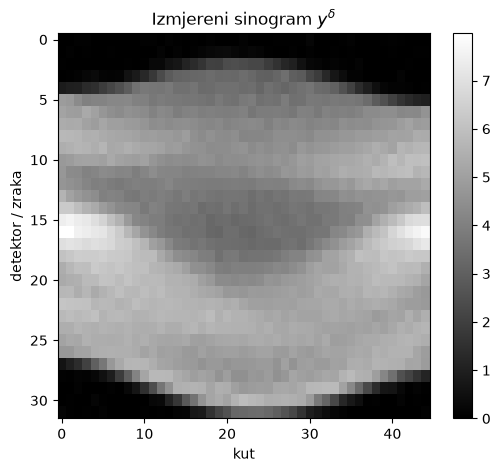

In [ ]:
import numpy as np
import scipy.io as sio
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Učitavamo matricu projekcije A i sinogram S.
mat = sio.loadmat(data_dir / "sinogram.mat")

# Projekcijska matrica A može biti učitana kao sparse ili kao obična matrica.
# Zato je učitavamo robusno i pretvaramo u CSR sparse format.
A_raw = mat["A"]

if sp.issparse(A_raw):
    A = A_raw.tocsr()
else:
    A = sp.csr_matrix(A_raw)

# Sinogram kao matrica K x M
S = np.asarray(mat["S"])

# Osnovni parametri eksperimenta
N = int(np.asarray(mat["N"]).item())    # dimenzija slike: N x N
M = int(np.asarray(mat["M"]).item())    # broj kutova
K = int(np.asarray(mat["K"]).item())    # broj zraka po kutu

# MATLAB-ov S(:) koristi stupčanu vektorizaciju, zato order="F".
y = S.reshape(-1, order="F")

if S.shape != (K, M) or A.shape != (K * M, N * N):
    raise ValueError(
        f"Nepodudarne dimenzije: S={S.shape}, A={A.shape}, "
        f"očekivano {(K, M)} i {(K * M, N * N)}."
    )

print("Dimenzija slike N x N:", N, "x", N)
print("Broj kutova M:", M)
print("Broj zraka po kutu K:", K)
print("Oblik sinograma S:", S.shape)
print("Oblik matrice A:", A.shape)
print("Broj nenultih elemenata u A:", A.nnz)

plt.figure(figsize=(6, 5))
plt.imshow(S, aspect="auto", cmap="gray")
plt.title("Izmjereni sinogram $y^\\delta$")
plt.xlabel("kut")
plt.ylabel("detektor / zraka")
plt.colorbar()
plt.show()


## 7. Početna FBP rekonstrukcija

FBP tj. filtrirana povratna projekcija se koristi kao referentna metoda za usporedbu s TV regularizacijom. 
Ona je klasična brza metoda za tomografsku rekonstrukciju, ali dobro radi samo kada imamo dovoljno kutova i malo šuma, jer kod rijetkih ili šumnih podataka često proizvodi artefakte.

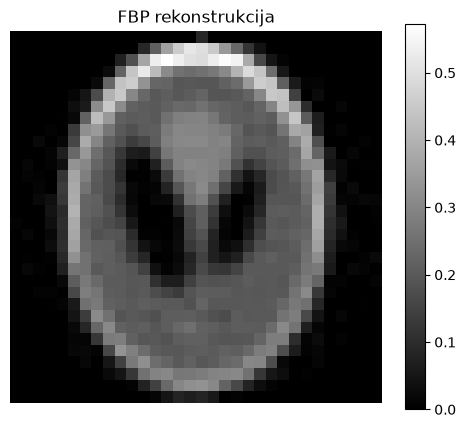

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import iradon

# Ako su kutovi spremljeni u .mat datoteci, koristimo njih.
# Inače ih generiramo ravnomjerno od 0 do 180 stupnjeva.
if "theta" in mat:
    theta_angles = np.asarray(mat["theta"]).ravel()
else:
    theta_angles = np.linspace(0, 180, M, endpoint=False)

# skimage.iradon očekuje sinogram oblika:
# broj_detektora x broj_kutova, dakle K x M.
fbp = iradon(
    S,
    theta=theta_angles,
    filter_name="ramp",
    circle=True,
    output_size=N
)

# Fizikalno očekujemo nenegativnu atenuaciju.
fbp = np.maximum(fbp, 0)

plt.figure(figsize=(6, 5))
plt.imshow(fbp, cmap="gray")
plt.title("FBP rekonstrukcija")
plt.axis("off")
plt.colorbar()
plt.show()

## 8. Diskretni operator gradijenta

TV regularizacija koristi diskretne horizontalne i vertikalne razlike. Inspirirano materijalima sa predavanja, konstruiraju se matrice $L_H$ i $L_V$ s periodičkim rubnim uvjetima.

Za sliku $x$ vrijedi

$$
Dx = \begin{bmatrix}L_Hx\\L_Vx\end{bmatrix}.
$$

Anizotropna totalna varijacija je

$$
\|Dx\|_1 = \|L_Hx\|_1+\|L_Vx\|_1.
$$

In [ ]:
def build_difference_matrices(N):
    """Konstruira LH i LV kao u materijalima za TV regularizaciju.

    Koristi se stupčana vektorizacija slike, kompatibilna s MATLAB-om:
    x = image.reshape(-1, order="F").
    """
    # Horizontalne razlike unutar svakog retka/stupca bloka, s periodičkim rubom.
    block = sp.diags(
        diagonals=[np.ones(N), -np.ones(N), np.ones(N)],
        offsets=[1 - N, 0, 1],
        shape=(N, N),
        format="csr"
    )
    LH = sp.block_diag([block for _ in range(N)], format="csr")

    # Vertikalne razlike: pomak za N mjesta u vektoriziranoj slici.
    LV = sp.diags(
        diagonals=[np.ones(N * N), -np.ones(N * N), np.ones(N * N)],
        offsets=[-N * N + N, 0, N],
        shape=(N * N, N * N),
        format="csr"
    )
    return LH.tocsr(), LV.tocsr()


LH, LV = build_difference_matrices(N)
D = sp.vstack([LH, LV], format="csr")

print("Oblik LH:", LH.shape)
print("Oblik LV:", LV.shape)
print("Oblik D:", D.shape)
print("Broj nenultih elemenata u D:", D.nnz)

Oblik LH: (1024, 1024)
Oblik LV: (1024, 1024)
Oblik D: (2048, 1024)
Broj nenultih elemenata u D: 4096


## 9. Definicija funkcije cilja

Za dano $\lambda$ minimiziramo

$$
J_\lambda(x)=\frac12\|Ax-y\|_2^2+\lambda\|Dx\|_1,
\qquad x\ge 0.
$$


In [ ]:
def objective(A, D, y, x, lam):
    """Vrati podatkovni dio, TV dio i ukupnu vrijednost funkcije cilja."""
    residual = A @ x - y
    data_term = 0.5 * np.linalg.norm(residual)**2
    tv_term = lam * np.linalg.norm(D @ x, 1)
    return data_term, tv_term, data_term + tv_term


def vec_to_img(x, N=N):
    """Vektor -> slika, uz MATLAB/stupčanu vektorizaciju."""
    return x.reshape((N, N), order="F")


def img_to_vec(img):
    """Slika -> vektor, uz MATLAB/stupčanu vektorizaciju."""
    return img.reshape(-1, order="F")

## 10. Procjena norme operatora $K=[A;D]$

Chambolle–Pockova metoda traži korake $\tau$ i $\sigma$ takve da

$$
\tau\sigma\|K\|^2 < 1,
\qquad
K=\begin{bmatrix}A\\D\end{bmatrix}.
$$

Koristimo `svds` za najveću singularnu vrijednost sparse matrice $[A;D]$.

In [ ]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla

Kop = sp.vstack([A, D], format="csr")

# Najveća singularna vrijednost operatora K=[A;D].
# Za veliki problem ovo može potrajati, ali dovoljno je izračunati jednom.
L = spla.svds(Kop, k=1, return_singular_vectors=False)[0]

tau = 0.99 / L
sigma = 0.99 / L
theta_cp = 1.0

print("Procijenjena norma ||K|| =", L)
print("tau =", tau)
print("sigma =", sigma)
print("tau * sigma * ||K||^2 =", tau * sigma * L**2)

Procijenjena norma ||K|| = 35.7805297666633
tau = 0.027668679207829464
sigma = 0.027668679207829464
tau * sigma * ||K||^2 = 0.9801000000000001


## 11. Chambolle–Pock algoritam za TV rekonstrukciju

Dualna varijabla $q$ pripada podatkovnom članu, a dualna varijabla $z$ pripada TV članu.

Ažuriranja su:

$$
q^{k+1}=\frac{q^k+\sigma(A\bar x^k-y)}{1+\sigma},
$$

$$
z^{k+1}=\lambda\frac{z^k+\sigma D\bar x^k}{\max(\lambda,|z^k+\sigma D\bar x^k|)},
$$

$$
x^{k+1}=\max(x^k-\tau A^Tq^{k+1}-\tau D^Tz^{k+1},0),
$$

$$
\bar x^{k+1}=x^{k+1}+\theta(x^{k+1}-x^k).
$$

U trećem retku `max(...,0)` je projekcija na uvjet $x\ge 0$.

In [ ]:
def chambolle_pock_tv(A, D, y, lam=1e-3, tau=None, sigma=None, theta=1.0,
                       n_iter=3000, print_every=300, verbose=True):
    """Chambolle--Pock metoda, sa parametrima tau, sigma i theta
    Parametri
    A : scipy sparse matrix
        Diskretna Radonova/Roentgenova transformacija.
    D : scipy sparse matrix
        Diskretni gradijent slike.
    y : np.ndarray
        Sinogram zapisan kao vektor.
    lam : float
        TV regularizacijski parametar.
    tau, sigma : float
        Primalni i dualni korak.
    theta : float
        Ekstrapolacijski parametar, obično 1.
    n_iter : int
        Broj iteracija.
    verbose : bool
        Ispisuje informacije o konvergenciji ako je True.
    """
    if tau is None or sigma is None:
        K = sp.vstack([A, D], format="csr")
        L = spla.svds(K, k=1, return_singular_vectors=False)[0]
        tau = 0.99 / L
        sigma = 0.99 / L

    n_pixels = A.shape[1]
    n_data = A.shape[0]
    n_grad = D.shape[0]

    # Primalna varijabla: slika x.
    x = np.zeros(n_pixels)
    x_hat = x.copy()

    # Dualne varijable.
    q = np.zeros(n_data)
    z = np.zeros(n_grad)

    history = {
        "iter": [],
        "data": [],
        "tv": [],
        "objective": [],
        "residual_norm": []
    }

    for k in range(1, n_iter + 1):
        # 1. Dualni korak za podatkovni član 1/2||Ax-y||^2.
        q = (q + sigma * (A @ x_hat - y)) / (1.0 + sigma)

        # 2. Dualni korak za TV član: projekcija na l_inf kuglu radijusa lam.
        w = z + sigma * (D @ x_hat)
        z = lam * w / np.maximum(lam, np.abs(w))

        # 3. Primalni korak i projekcija na nenegativne slike.
        x_old = x.copy()
        x = np.maximum(x - tau * (A.T @ q + D.T @ z), 0.0)

        # 4. Ekstrapolacija.
        x_hat = x + theta * (x - x_old)

        if (k % print_every == 0) or (k == 1) or (k == n_iter):
            data_term, tv_term, obj = objective(A, D, y, x, lam)
            res_norm = np.linalg.norm(A @ x - y)
            history["iter"].append(k)
            history["data"].append(data_term)
            history["tv"].append(tv_term)
            history["objective"].append(obj)
            history["residual_norm"].append(res_norm)
            if verbose:
                print(f"iter={k:5d} | J={obj:.4e} | data={data_term:.4e} | TV={tv_term:.4e} | ||Ax-y||={res_norm:.4e}")

    return x, history


## 12. Početni TV pokušaj: preslab parametar $\lambda=10^{-3}$

Regularizacijski parametar određuje kompromis između podudarnosti s mjerenjima i TV zaglađivanja. Premala vrijednost može pratiti šum, dok prevelika uklanja i korisne detalje.

Najprije prikazujemo početnu vrijednost $\lambda=10^{-3}$, korištenu kao **polazni primjer**, a ne kao konačan izbor. U odjeljku 16 odabrat ćemo $\lambda$ Morozovljevim pravilom diskrepancije i usporediti rezultate.


In [ ]:
lam_tv = 1e-3
n_iter = 3000  # za brzu probu smanjiti na 500; za bolju sliku povećati na 10000

x_tv, hist_tv = chambolle_pock_tv(
    A=A,
    D=D,
    y=y,
    lam=lam_tv,
    tau=tau,
    sigma=sigma,
    theta=theta_cp,
    n_iter=n_iter,
    print_every=max(1, n_iter // 10)
)

img_tv = vec_to_img(x_tv)

iter=    1 | J=8.4826e+02 | data=8.4824e+02 | TV=1.6161e-02 | ||Ax-y||=4.1188e+01
iter=  300 | J=2.6536e+00 | data=2.5222e+00 | TV=1.3140e-01 | ||Ax-y||=2.2460e+00
iter=  600 | J=2.6518e+00 | data=2.5187e+00 | TV=1.3316e-01 | ||Ax-y||=2.2444e+00
iter=  900 | J=2.6518e+00 | data=2.5184e+00 | TV=1.3340e-01 | ||Ax-y||=2.2443e+00
iter= 1200 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3344e-01 | ||Ax-y||=2.2443e+00
iter= 1500 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00
iter= 1800 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00
iter= 2100 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00
iter= 2400 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00
iter= 2700 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00
iter= 3000 | J=2.6518e+00 | data=2.5183e+00 | TV=1.3346e-01 | ||Ax-y||=2.2442e+00


In [ ]:
plt.figure(figsize=(6, 5))
plt.imshow(img_tv, cmap="gray")
plt.title(f"Početni TV, lambda={lam_tv}")
plt.axis("off")
plt.colorbar()
plt.show()


## 13. Početna usporedba FBP-a i TV-a

FBP rekonstruira osnovni oblik fantoma, ali pokazuje zamućenje rubova. Za početnu vrijednost $\lambda=10^{-3}$ TV rekonstrukcija zadržava izražene oscilacije i njezina je relativna pogreška usporediva s FBP-om. To **nije konačna ocjena TV regularizacije**: odjeljak 16 pokazuje kako pravilno odabrana vrijednost parametra znatno poboljšava rekonstrukciju.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(fbp, cmap="gray")
axes[0].set_title("FBP")
axes[0].axis("off")

axes[1].imshow(img_tv, cmap="gray")
axes[1].set_title("TV, početni $\\lambda=10^{-3}$")
axes[1].axis("off")

plt.tight_layout()
plt.show()


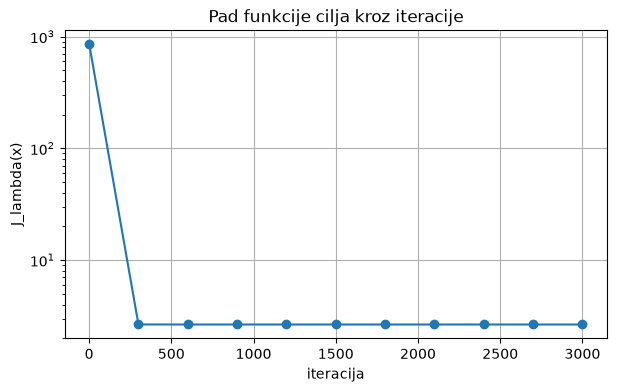

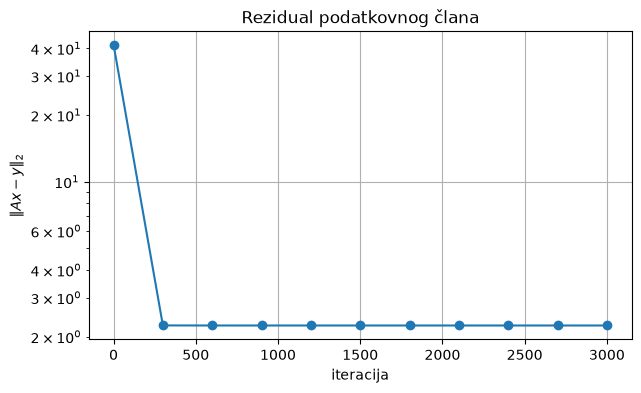

In [ ]:
# Graf konvergencije funkcije cilja.
plt.figure(figsize=(7, 4))
plt.semilogy(hist_tv["iter"], hist_tv["objective"], marker="o")
plt.xlabel("iteracija")
plt.ylabel("J_lambda(x)")
plt.title("Pad funkcije cilja kroz iteracije")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.semilogy(hist_tv["iter"], hist_tv["residual_norm"], marker="o")
plt.xlabel("iteracija")
plt.ylabel(r"$\|Ax-y\|_2$")
plt.title("Rezidual podatkovnog člana")
plt.grid(True)
plt.show()

Prvi graf: Funkcija cilja drastično pada u početnom dijelu algoritma tj. Chambolle–Pock metoda vrlo brzo smanjuje razliku između projekcija rekonstruirane slike i izmjerenog sinograma. Nakon inicijalnog pada, funkcija cilja se stabilizira, pa dodatne iteracije donose samo male promjene u rekonstrukciji. Takvo ponašanje i očekujemo od iterativne metode: u prvim iteracijama dobivamo najveće poboljšanje, dok se kasnije algoritam približava stacionarnom rješenju.
Drugi graf prikazuje promjenu podatkovnog reziduala $\|Ax-y\|_2$ kroz iteracije. Rezidual vrlo brzo pada u početnim iteracijama, što znači da rekonstruirana slika već rano postaje konzistentna s izmjerenim sinogramom, zatim se krivulja  stabilizira. Dodatne iteracije ne donose bitno bolje slaganje s mjerenjima. Ponovo, to je očekivano jer TV regularizacija ne minimizira samo podatkovni član, nego traži kompromis između vjernosti podacima i pravilnosti rekonstrukcije. Ako bi se podatkovni rezidual previše forsirao, metoda bi mogla početi rekonstruirati i šum iz mjerenja.

## 14. Utjecaj parametra $\lambda$

Tri vrijednosti prikazuju razliku između preslabe regularizacije ($\lambda=10^{-3}$), srednje vrijednosti ($\lambda=0.1$) i vrijednosti bliske izboru pravilom diskrepancije ($\lambda=0.32$). To je ilustrativna usporedba; **postupak određivanja** Morozovljeva parametra nalazi se u odjeljku 16. Pri numeričkoj usporedbi broj iteracija ostaje jednak za sve tri vrijednosti.


In [ ]:
run_lambda_sweep = True

if run_lambda_sweep:
    lambdas = [1e-3, 0.1, 0.32]
    reconstructions = []

    for lam in lambdas:
        print("\nPokrećem TV rekonstrukciju za lambda =", lam)

        x_rec, hist = chambolle_pock_tv(
            A=A, D=D, y=y,
            lam=lam,
            tau=tau, sigma=sigma, theta=theta_cp,
            n_iter=3000,
            print_every=1000
        )

        reconstructions.append(vec_to_img(x_rec))

    fig, axes = plt.subplots(1, len(lambdas), figsize=(15, 5))

    for ax, lam, rec in zip(axes, lambdas, reconstructions):
        ax.imshow(rec, cmap="gray")
        ax.set_title(f"$\\lambda={lam}$")
        ax.axis("off")

    plt.suptitle("Utjecaj regularizacijskog parametra $\\lambda$ na TV rekonstrukciju")
    plt.tight_layout()
    plt.show()

else:
    print("Lambda sweep nije pokrenut. Za pokretanje postavi run_lambda_sweep = True.")


## 15. Usporedba sa Tikhonovljevom regularizacijom

Ovdje rješavamo

$$
\min_x \; \|Ax-y\|_2^2 + \alpha^2\|x\|_2^2.
$$

Tikhonov često daje glatke rekonstrukcije, ali može zamutiti rubove, zato je TV regularizacija bolja kada očekujemo oštre rubove.

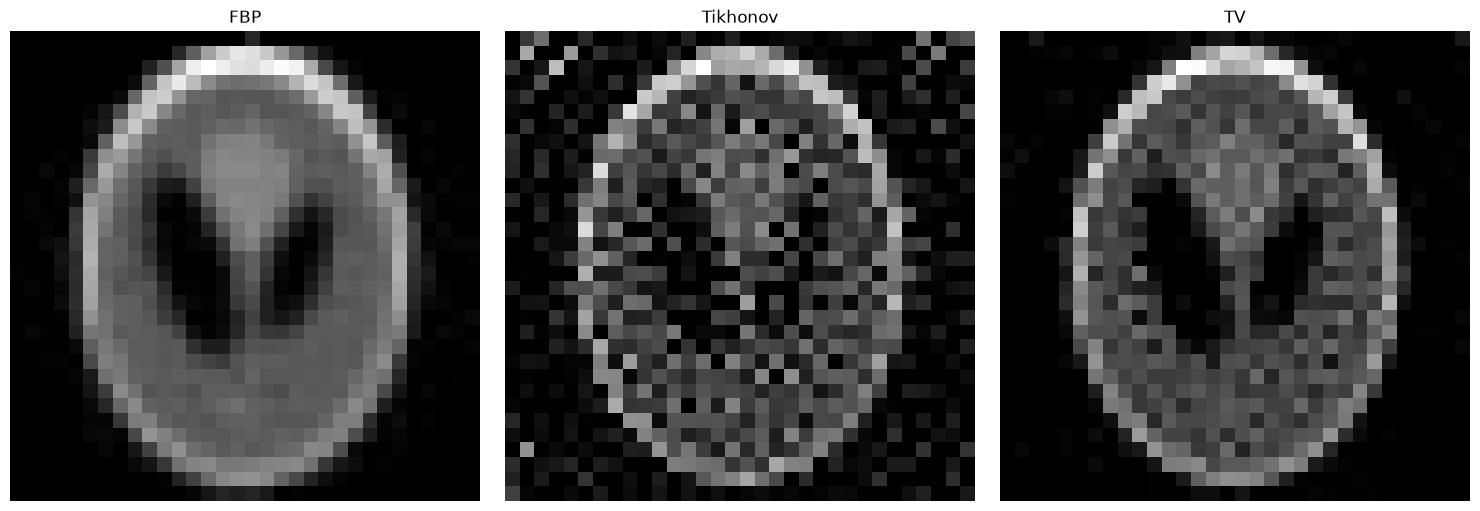

In [ ]:
run_tikhonov = True

if run_tikhonov:
    alpha = 0.1
    I = sp.eye(A.shape[1], format="csr")
    A_aug = sp.vstack([A, alpha * I], format="csr")
    y_aug = np.concatenate([y, np.zeros(A.shape[1])])

    # lsqr je iterativni solver za velike sparse probleme najmanjih kvadrata.
    xtik = spla.lsqr(A_aug, y_aug, iter_lim=500, atol=1e-6, btol=1e-6)[0]
    img_tik = vec_to_img(np.maximum(xtik, 0))

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(fbp, cmap="gray")
    axes[0].set_title("FBP")
    axes[0].axis("off")

    axes[1].imshow(img_tik, cmap="gray")
    axes[1].set_title("Tikhonov")
    axes[1].axis("off")

    axes[2].imshow(img_tv, cmap="gray")
    axes[2].set_title("TV")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

## 16. Izbor parametra $\lambda$ Morozovljevim pravilom diskrepancije

Korištenje nekoliko unaprijed zadanih vrijednosti u odjeljku 14 ilustrira utjecaj regularizacije. Sustavniji odabir temelji se na razini šuma $\delta$ u mjerenjima. Morozovljevo pravilo diskrepancije traži parametar $\lambda$ za koji vrijedi

$$
\|Ax_\lambda-y^\delta\|_2\approx\delta.
$$

Za sintetičke podatke poznajemo i čisti sinogram $y^0$, pa razinu šuma računamo kao

$$
\delta=\|y^\delta-y^0\|_2.
$$

Ako je rezidual znatno manji od $\delta$, model se može prilagođavati šumu; ako je znatno veći, podaci nisu dovoljno dobro opisani. Parametar određujemo bisekcijom po $\log\lambda$ u intervalu $[10^{-2},1]$, uz rješavanje TV problema za svaku probnu vrijednost.

Budući da su podaci sintetički, poznajemo i originalnu sliku $x_{\mathrm{true}}$. Ona se **ne koristi pri izboru** $\lambda$, nego samo za naknadnu provjeru kvalitete preko relativne pogreške

$$
\mathrm{RelErr}(x)=\frac{\|x-x_{\mathrm{true}}\|_2}{\|x_{\mathrm{true}}\|_2}.
$$

Za stvarna mjerenja, kada $y^0$ nije poznat, razinu šuma potrebno je zasebno procijeniti.


In [ ]:
# Čisti sinogram i originalna slika (podaci su sintetički).
# U kodu je y izmjereni (šumni) sinogram, a y_clean čisti.
y_clean = np.asarray(mat["S_clean"]).reshape(-1, order="F")
x_true = np.asarray(mat["x_true"]).reshape(-1, order="F")

# Razina šuma.
delta = np.linalg.norm(y - y_clean)


def rel_err(x):
    """Relativna greška rekonstrukcije u odnosu na originalnu sliku."""
    return np.linalg.norm(x - x_true) / np.linalg.norm(x_true)


def tv_quiet(lam, n_iter=3000):
    """TV rekonstrukcija bez ispisa iteracija."""
    x, _ = chambolle_pock_tv(A, D, y, lam=lam, tau=tau, sigma=sigma,
                             theta=theta_cp, n_iter=n_iter,
                             print_every=n_iter, verbose=False)
    return x


# Bisekcija po log(lambda): rezidual raste s lambda.
lo, hi = np.log(1e-2), np.log(1.0)
for _ in range(12):
    lam_mor = np.exp(0.5 * (lo + hi))
    x_mor = tv_quiet(lam_mor)
    if np.linalg.norm(A @ x_mor - y) < delta:
        lo = np.log(lam_mor)   # rezidual manji od šuma: treba jače regularizirati
    else:
        hi = np.log(lam_mor)

print(f"razina šuma delta = {delta:.3f}")
print(f"rezidual za lambda = 1e-3: {np.linalg.norm(A @ x_tv - y):.3f}")
print(f"Morozovljev lambda = {lam_mor:.3f}, rezidual = {np.linalg.norm(A @ x_mor - y):.3f}")
print()
print("Relativna greška u odnosu na originalnu sliku:")
print(f"  FBP:                   {rel_err(img_to_vec(fbp)):.3f}")
if run_tikhonov:
    print(f"  Tikhonov, alpha = {alpha}: {rel_err(np.maximum(xtik, 0)):.3f}")
print(f"  TV, lambda = 1e-3:     {rel_err(x_tv):.3f}")
print(f"  TV, Morozov lambda:    {rel_err(x_mor):.3f}")


razina šuma delta = 3.234
rezidual za lambda = 1e-3: 2.244
Morozovljev lambda = 0.321, rezidual = 3.234

Relativna greška u odnosu na originalnu sliku:
  FBP:                   0.184
  Tikhonov, alpha = 0.1: 0.487
  TV, lambda = 1e-3:     0.180
  TV, Morozov lambda:    0.102


Najmanja greška na krivulji je 0.075, za lambda = 0.1.


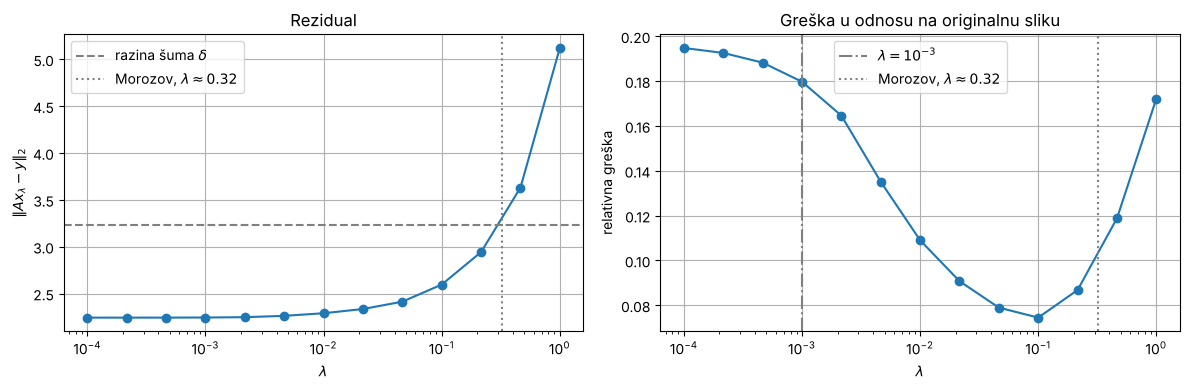

In [ ]:
# Rezidual i relativna greška u širokom rasponu vrijednosti lambda.
lambdas_wide = np.logspace(-4, 0, 13)
residuals, errors = [], []
for lam in lambdas_wide:
    x_lam = tv_quiet(lam)
    residuals.append(np.linalg.norm(A @ x_lam - y))
    errors.append(rel_err(x_lam))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].semilogx(lambdas_wide, residuals, marker="o")
axes[0].axhline(delta, color="gray", linestyle="--", label=r"razina šuma $\delta$")
axes[0].axvline(lam_mor, color="gray", linestyle=":", label=fr"Morozov, $\lambda\approx{lam_mor:.2f}$")
axes[0].set_xlabel(r"$\lambda$")
axes[0].set_ylabel(r"$\Vert Ax_\lambda-y\Vert_2$")
axes[0].set_title("Rezidual")
axes[0].legend()
axes[0].grid(True)

axes[1].semilogx(lambdas_wide, errors, marker="o")
axes[1].axvline(1e-3, color="gray", linestyle="-.", label=r"$\lambda=10^{-3}$")
axes[1].axvline(lam_mor, color="gray", linestyle=":", label=fr"Morozov, $\lambda\approx{lam_mor:.2f}$")
axes[1].set_xlabel(r"$\lambda$")
axes[1].set_ylabel("relativna greška")
axes[1].set_title("Greška u odnosu na originalnu sliku")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

k_best = int(np.argmin(errors))
print(f"Najmanja greška na krivulji je {errors[k_best]:.3f}, za lambda = {lambdas_wide[k_best]:.2g}.")

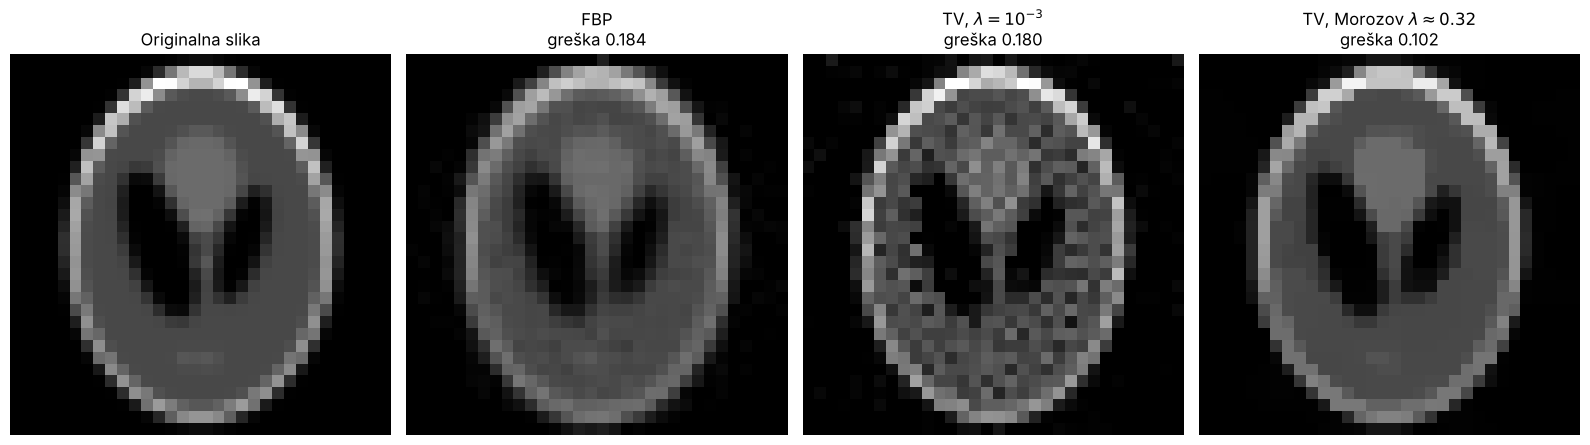

In [ ]:
# Usporedba s originalnom slikom; sve slike imaju istu skalu sivih tonova.
images = [
    (vec_to_img(x_true), "Originalna slika"),
    (fbp, f"FBP\ngreška {rel_err(img_to_vec(fbp)):.3f}"),
    (img_tv, f"TV, $\\lambda=10^{{-3}}$\ngreška {rel_err(x_tv):.3f}"),
    (vec_to_img(x_mor), f"TV, Morozov $\\lambda\\approx{lam_mor:.2f}$\ngreška {rel_err(x_mor):.3f}"),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (img, title) in zip(axes, images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=x_true.max())
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

Za $\lambda=10^{-3}$ rezidual približno $2.24$ manji je od razine šuma $\delta\approx3.23$, što upućuje na preslabu regularizaciju. Zato početna TV rekonstrukcija po relativnoj pogrešci ($0.180$) nije bolja od FBP-a ($0.184$). Morozovljevo pravilo daje $\lambda\approx0.32$: tada rezidual približno odgovara razini šuma, a relativna pogreška smanjuje se na $0.102$.

Na prikazanoj mreži vrijednosti najmanju relativnu pogrešku ($0.075$ za $\lambda=0.1$) dobivamo **uz poznavanje originalne slike**. Stoga $\lambda\approx0.32$ nije globalno optimalan u smislu najmanje poznate relativne pogreške, nego podatkovno opravdan izbor koji ne zahtijeva poznavanje $x_{\mathrm{true}}$.


## 17. Interpretacija rezultata i komentari

FBP brzo rekonstruira osnovni oblik fantoma, ali rubovi ostaju zamućeni. Tikhonovljeva rekonstrukcija s fiksnim parametrom $\alpha=0.1$ u prikazanom eksperimentu ima više artefakata i relativnu pogrešku $0.487$. Budući da $\alpha$ nije optimiran, taj rezultat ne znači da je Tikhonovljeva metoda općenito lošija od TV-a.

TV rekonstrukcija s početnim $\lambda=10^{-3}$ ima zrnatu unutrašnjost fantoma i relativnu pogrešku $0.180$, praktički jednaku FBP-u ($0.184$). Taj parametar dopušta da rezidual padne ispod poznate razine šuma, tj. preslabo ograničava prilagođavanje šumu.

Morozovljevim pravilom dobivamo $\lambda\approx0.32$, pri kojem je rezidual oko $3.234$, približno jednak razini šuma. TV rekonstrukcija tada bolje čuva po dijelovima konstantne strukture i rubove, a relativna pogreška pada na $0.102$. Prema tom mjerilu, ovo je najbolja među **odabranim usporednim rekonstrukcijama** (FBP, početni TV, Tikhonov, Morozov TV).

Pri pretraživanju šireg raspona $\lambda$ na poznatoj originalnoj slici dobivena je još manja pogreška $0.075$ za $\lambda=0.1$. To služi kao analiza osjetljivosti; nije dopušteno koristiti tu pogrešku za izbor parametra u stvarnoj rekonstrukciji u kojoj originalna slika nije poznata.

Krivulje funkcije cilja i reziduala potvrđuju da algoritam najviše napreduje na početku, a potom se postupno stabilizira. Pri usporedbi različitih vrijednosti $\lambda$ koristimo isti broj iteracija.


## 18. Zaključak

Razmatrali smo diskretni tomografski model $y^\delta=Ax+\varepsilon$ i minimizirali

$$
\min_{x\ge0}\;\frac12\|Ax-y^\delta\|_2^2+\lambda\|Dx\|_1
$$

Chambolle–Pockovom primalno-dualnom metodom. TV regularizacija uvodi pretpostavku da je slika po dijelovima približno konstantna, pa može ublažiti šum uz očuvanje važnih rubova.

Na korištenom sintetičkom skupu podataka početna vrijednost $\lambda=10^{-3}$ daje relativnu pogrešku $0.180$, dok FBP daje $0.184$. Morozovljevo pravilo diskrepancije uz poznatu razinu šuma $\delta\approx3.234$ bira $\lambda\approx0.321$ i smanjuje pogrešku na $0.102$. Izbor parametra stoga bitno utječe na kvalitetu rekonstrukcije.

Najmanja pogreška na dodatnoj ispitanoj mreži ($0.075$ pri $\lambda=0.1$) može se identificirati samo zahvaljujući poznatoj originalnoj slici. Prednost Morozovljeva pravila nije jamstvo najmanje rekonstrukcijske pogreške, nego mogućnost izbora parametra **bez korištenja originalne slike**, na temelju procijenjene razine šuma.


## 19. Gdje dalje?

Projekt bi se mogao dalje proširiti u jednom od dvaju smjerova:

1. **Rijetki i šumni podaci.**  
   Umjesto punog skupa projekcija, možemo koristiti manji broj kutova, npr. $M=10,20,30$ i dodati šum u sinogram:

   $$
   y^\delta = y + \eta.
   $$

   Zatim bi usporedili kako FBP i TV rekonstrukcija ovise o broju projekcija i razini šuma.

2. **Procjena razine šuma.**  
   Pravilo diskrepancije u odjeljku 16 koristi točnu razinu šuma $\delta$, koju znamo jer su podaci sintetički. U stvarnom mjerenju $\delta$ treba procijeniti iz samih podataka, pa bi trebalo ispitati koliko je izbor $\lambda$ osjetljiv na pogrešku u toj procjeni.